# Single-cell differential expression with MAST

**Author:** Tahila Andrighetti
**Last updated:** October 2026

> Code review, refactoring and documentation were developed with the assistance
> of [Claude Code](https://claude.com/claude-code) (Anthropic). All analytical
> choices were reviewed by the author.

# Overview

This tutorial shows how to find differentially expressed genes (DEGs) between
two conditions, inside each cell type, with **MAST** [Finak et al., 2015].
MAST is an R package. Here it is called from Python through the `sctools.mast`
module (`RunMAST` and `RunMASTByCelltype`), which uses `rpy2`.

What the tutorial covers:

1. How the MAST model works, and what its results mean.
2. How to choose the model: cells as replicates (`glm`) or samples as
   replicates (`glmer`).
3. What each parameter does, and which value to use.
4. How to read the results table, and how to plot it.
5. The limits of the analysis, both of MAST and of the example dataset.

**How to read the options.** When a step has two valid options for different
situations, the text shows both, with a code example. The code cell uses the
option that fits the example dataset, with a short justification.

> **Conda environment**
> - `scRNA_NEW`: Python with `rpy2` and `anndata2ri`, and R with the `MAST`
>   package (tested with MAST 1.28.0). `model="glmer"` also needs the R package
>   `lme4` (installed in `scRNA_NEW`, not in `scRNA_NEW_pt2`).
> - If you run the code outside Jupyter, activate the environment first, so
>   that `rpy2` finds R.

References: [Finak et al., 2015](https://doi.org/10.1186/s13059-015-0844-5);
[MAST on Bioconductor](https://bioconductor.org/packages/MAST).

## About the example dataset

We use the bone marrow neutrophils of the public dataset of Sheng et al.
(2025), which compared germ-free (GF) and specific pathogen-free (SPF) mice
to study how the absence of microbiota affects immune development.

| Sample | Condition | GEO sample | SRA run |
|---|---|---|---|
| `49` | SPF | GSM8943511 | SRR33239249 |
| `50` | GF | GSM8943510 | SRR33239250 |

- Mice: Kunming (KM) strain, male, 10 weeks old. Kunming is an outbred stock.
- Library: 10x Genomics Chromium Single Cell 3' v3.1. Data: GEO
  [GSE295200](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE295200).
- We processed the raw data again (Cell Ranger, SoupX, QC, integration) and
  annotated the neutrophils in the maturation stages G0 to G5c of Xie et al.
  (2020). The original study used another annotation (populations P1 to P4).
- We test each stage separately. GF mice have fewer neutrophils [Sheng et al.,
  2025], so the stage proportions can differ between conditions. Testing inside
  each stage avoids calling a change in stage composition a change in gene
  expression.

> **Caveat: one sample per condition.** This dataset has **one animal per
> condition** (n = 1 GF and n = 1 SPF in the bone marrow). For differential
> expression this is a strong limit:
>
> 1. **Condition and animal are the same factor.** The test compares two mice.
>    Any difference between them (genetic background of an outbred stock,
>    handling, sample processing, library, sequencing depth) looks like a GF vs
>    SPF effect.
> 2. **The p-values do not test the condition.** With n = 1, there is no estimate
>    of the variation between animals. MAST then uses the cells as replicates.
>    With hundreds of cells, very small differences become "significant". This
>    is pseudoreplication [Zimmerman et al., 2021; Squair et al., 2021].
> 3. **A model with samples as replicates is not possible.** `model="glmer"` and
>    pseudobulk methods need at least two samples per condition (see section 3).
> 4. **Results are hypotheses.** Use the effect size (log2 fold change and its
>    confidence interval) and the detection rate to rank genes, not the p-value
>    alone. Confirm interesting genes in data with biological replicates.
>
> We use this dataset because it is public and shows all the steps. It is not a
> model for the study design.

References: [Sheng et al., 2025](https://doi.org/10.24272/j.issn.2095-8137.2024.467);
[Xie et al., 2020](https://doi.org/10.1038/s41590-020-0736-z).

# 1. Load the data

The input is an AnnData with:

- a **counts layer** with untransformed counts (here `QC_filtered`: counts after
  SoupX ambient RNA correction and QC). Do not use a log-normalized layer:
  `RunMAST` normalizes the counts itself.
- `obs` columns with the **cell type** (`celltype`), the **condition**
  (`condition`) and the **biological sample** (`sample`).

In [14]:
import pandas as pd
import scanpy as sc
from sctools import RunMAST, RunMASTByCelltype
from sctools.degs import VolcanoGridByGroup
from sctools.plots import PlotHeatmap
from sctools.functionalanalysis import PrepareULMInput

# Example dataset: bone marrow neutrophils, GF and SPF (Sheng et al. 2025).
data_dir = "/media/tahila/DADOS/HD/2609_scNeuSheng/"
adata = sc.read_h5ad(f"{data_dir}/06.scNeuSheng.neutrophils_annotated.h5ad")

In [15]:
adata

AnnData object with n_obs × n_vars = 10614 × 33696
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'is_doublet', 'leiden_res1', 'leiden_res1.3', 'leiden_res1.4', 'leiden_res1.5', 'leiden_res1.6', 'leiden_res1.8', 'leiden_res2', 'leiden_res0.8', 'S_score', 'G2M_score', 'phase', 'score_G0', 'score_G1', 'score_G2', 'score_G3', 'score_G4', 'score_G5a', 'score_G5b', 'score_G5c', 'aucell_G0', 'aucell_G1', 'aucell_G2', 'aucell_G3', 'aucell_G4', 'aucell_G5a', 'aucell_G5b', 'aucell_G5c', 'celltype'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection

Check how many cells each condition and sample has in each stage. Small groups
give unstable results, and `RunMASTByCelltype` skips groups below
`min_cells_per_group`.

In [16]:
adata.obs['condition'].value_counts()

condition
SPF    5397
GF     5217
Name: count, dtype: int64

In [17]:
# Cells per stage, condition and sample.
# In the example dataset each condition has one sample (49 = SPF, 50 = GF).
pd.crosstab(adata.obs["celltype"], [adata.obs["condition"], adata.obs["sample"]])

condition,GF,SPF
sample,50,49
celltype,,
G0,184,162
G1,197,223
G2,576,663
G3,1176,1482
G4,1566,1665
G5a,809,579
G5b,24,79
G5c,685,544


# 2. How MAST works

Single-cell data have many zeros. A zero can mean that the gene is off, or that
it was expressed but not captured. MAST models each gene with a two-part
**hurdle model** [Finak et al., 2015]:

| Part | Question | Model |
|---|---|---|
| Discrete (`D`) | Is the gene detected in the cell (count > 0)? | Logistic regression. |
| Continuous (`C`) | When it is detected, how high is its expression? | Linear (Gaussian) model on the log-expression, only in cells where the gene is detected. |

Both parts use the same covariates. The test for the condition is a
**likelihood ratio test (LRT)** that combines both parts. A gene can be
differentially expressed because it is detected in more cells, because it is
higher when detected, or both.

**Cellular detection rate (CDR).** The fraction of genes detected in each cell
changes with cell size, cell state and capture efficiency, and it affects all
genes at once. MAST recommends it as a covariate [Finak et al., 2015].
`RunMAST` always adds it as `ngeneson`: the number of detected genes per cell
(after the gene filter), scaled. You do not need to pass it.

**Input scale.** MAST expects log-transformed expression. `RunMAST` normalizes
the counts to `target_sum` counts per cell, then applies `log1p`. MAST gives
the fold change in natural-log units; `RunMAST` converts it to log2 units.

**Domain note:** the MAST `log2FoldChange` is the change in the **expected
value of log1p(normalized expression)**, combining the discrete and continuous
parts. It is not the log2 ratio of the mean counts, as in pseudobulk DESeq2. It
also depends on `target_sum`: the pseudocount of 1 in `log1p` is relative to
the library size. So compare fold changes only between analyses with the same
`target_sum`.

References: [Finak et al., 2015](https://doi.org/10.1186/s13059-015-0844-5);
[Soneson and Robinson, 2018](https://doi.org/10.1038/nmeth.4612).

# 3. Choose the model

`RunMAST` has no default model, on purpose. The choice depends on the design:

| `model` | Formula | Replicate unit | When to use |
|---|---|---|---|
| `"glm"` | `~ ngeneson + covariates + condition` | Each cell. | Exploration, or when there is only **one sample per condition** (no other option). With several samples per condition, p-values are much too small. |
| `"glmer"` | `~ ngeneson + covariates + condition + (1 \| sample)` | Each biological sample (random intercept). | At least two, better three or more, samples per condition. This is the MAST model with random effects that performed well in Zimmerman et al. (2021). Slower (about 2 minutes per cell type with 4 cores). |

**Pseudobulk as an alternative.** Summing the counts per sample and cell type,
then testing with a bulk method (e.g. DESeq2), is one of the most reliable
approaches to control false discoveries [Squair et al., 2021; Crowell et al.,
2020]. In `sctools` this is `sctools.degs.PseudoDESeq2`. It also needs
biological replicates. With replicates, it is a good cross-check of `glmer`.

With few samples per condition (e.g. 2 vs 2), the random-effect variance of
`glmer` is poorly estimated, so the results are still fragile. `RunMAST` logs a
warning in this case.

**Example dataset:** there is one sample per condition. In `glmer`, the random
intercept of each sample would be the same thing as the condition effect (two
samples, one per condition), so the model cannot separate them. So
**`model="glm"` is the only possible choice**. We still pass `sample_col`, so
`RunMAST` can check the design. Remember that these p-values compare the cells
of two animals.

Example with `glmer`, for data with several samples per condition:

```python
df, skipped = RunMASTByCelltype(
    adata,
    celltype_col="celltype",
    model="glmer",               # random intercept per sample
    condition_col="condition",
    ref_level="SPF",
    contrast_level="GF",
    sample_col="sample",         # required for glmer
    counts_layer="QC_filtered",
    min_samples_per_group=2,     # do not test a cell type with fewer samples
    n_cores=4,
)
```

References: [Zimmerman et al., 2021](https://doi.org/10.1038/s41467-021-21038-1);
[Squair et al., 2021](https://doi.org/10.1038/s41467-021-25960-2);
[Crowell et al., 2020](https://doi.org/10.1038/s41467-020-19894-4).

# 4. Run MAST per cell type

`RunMASTByCelltype` runs `RunMAST` for each cell type and returns one long table.
To test only one cell type, or all cells together, use `RunMAST` with the same
parameters (plus `celltype` and `celltype_col`). The input `adata` is never
modified.

### Parameters

| Parameter | Value here | What it does |
|---|---|---|
| `celltype_col` | `"celltype"` | `obs` column with the groups that are tested separately. |
| `celltypes` | `None` | Groups to test. `None` tests all of them (category order if categorical). |
| `model` | `"glm"` | `"glm"` or `"glmer"`, no default (see section 3). |
| `condition_col` | `"condition"` | `obs` column with the conditions. |
| `ref_level` | `"SPF"` | Reference level. |
| `contrast_level` | `"GF"` | Tested level. A **positive** `log2FoldChange` means **higher in GF**. |
| `sample_col` | `"sample"` | `obs` column with the biological sample (mouse, donor). Required for `glmer`. For `glm` it is used to check the design and to warn about pseudoreplication. |
| `counts_layer` | `"QC_filtered"` | Layer with untransformed counts (raw or ambient-corrected). Not a log-normalized layer. |
| `covariates` | `None` | Extra `obs` columns added as fixed effects (e.g. `["batch"]`, `["sex"]`). They must not be confounded with the condition. `ngeneson` (CDR) is always added. |
| `target_sum` | `1e4` | Counts per cell after normalization, before `log1p`. See below. |
| `freq_filter` | `0.1` | Keep genes detected (count > 0) in **more than** 10% of the tested cells (both conditions together). Genes below this have too few non-zero values for the continuous part. |
| `min_cells_per_group` | `20` | A cell type is skipped if one condition has fewer cells. |
| `min_cells_per_sample` | `10` | A sample counts for `min_samples_per_group` only if it has at least this many cells. |
| `min_samples_per_group` | `1` | Minimum number of samples per condition. With replicates, use 2 or more. |
| `glm_method` | `"bayesglm"` | Fitting method for `model="glm"` only. See below. |
| `ebayes` | `True` | Empirical Bayes shrinkage of the variance, for `model="glm"` only. See below. |
| `n_cores` | `4` | Number of R cores used by MAST. |

#### `target_sum`: 1e4 or 1e6

| Value | Effect | When to use |
|---|---|---|
| `1e4` (default) | Same normalization as the rest of `sctools` (`NormalizeLog1pFromLayer`). | Most analyses, so the fold changes match the other plots. |
| `1e6` (counts per million) | Larger `\|log2FoldChange\|` values, because the pseudocount of 1 is smaller relative to the counts. Closer to the MAST vignette, which uses log2(TPM + 1). | Only to compare with results made on this scale. |


#### `glm_method` and `ebayes` (only for `model="glm"`)

| Option | What it does | When to use |
|---|---|---|
| `glm_method="bayesglm"`, `ebayes=True` (MAST default) | `bayesglm` puts a weakly informative prior on the coefficients [Gelman et al., 2008]. It keeps the discrete part estimable when a gene is detected in almost all cells of a group. `ebayes` shrinks the variance of the continuous part toward a common value, which is more stable with few cells. | Most analyses. This is the setting of the official MAST vignette. |
| `glm_method="glm"`, `ebayes=False` | Plain maximum likelihood, no prior and no shrinkage. The discrete part often fails for genes with almost no zeros. | Only to reproduce older results made with these settings. |

`model="glmer"` ignores both options: it is fitted with `lme4` and
`ebayes=False`.

**Example dataset:** we use the MAST default (`"bayesglm"`, `ebayes=True`).

References: [Finak et al., 2015](https://doi.org/10.1186/s13059-015-0844-5);
[Gelman et al., 2008](https://doi.org/10.1214/08-AOAS191).

In [18]:
df, skipped = RunMASTByCelltype(
    adata,
    celltype_col="celltype",
    celltypes=None,                 # None = all celltypes
    model="glm",                   # one sample per condition: glm is the only option (section 3)
    condition_col="condition",
    ref_level="SPF",                 # positive log2FC = higher in contrast_level
    contrast_level="GF",
    sample_col="sample",            # biological replicate (mouse / donor)
    counts_layer="QC_filtered",     # SoupX-corrected counts; normalized inside the function
    covariates=None,                # e.g. ["batch"], must not be confounded with condition
    target_sum=1e6,                 # sctools default; 1e6 gives larger |log2FC|
    freq_filter=0.1,                # gene detected in more than 10% of tested cells
    min_cells_per_group=20,
    min_cells_per_sample=10,
    min_samples_per_group=1,
    glm_method="bayesglm",          # model="glm" only; MAST default
    ebayes=True,                    # model="glm" only
    n_cores=4,
)
skipped

INFO:sctools.mast:MAST: processing G0 ...
INFO:sctools.mast:G0: 346 cells ({'GF': 184, 'SPF': 162}), 9850 of 33696 genes pass freq_filter=0.1.
R[write to console]: `fData` has no primerid.  I'll make something up.

R[write to console]: `cData` has no wellKey.  I'll make something up.

R[write to console]: Assuming data assay in position 1, with name X is log-transformed.

R[write to console]: 
Done!

R[write to console]: Combining coefficients and standard errors

R[write to console]: Calculating log-fold changes

R[write to console]: Calculating likelihood ratio tests

R[write to console]: Refitting on reduced model...

R[write to console]: 
Done!

INFO:sctools.mast:G0: log2FoldChange taken from the continuous part for 0 gene(s) (discrete part not estimable, gene detected in almost all cells); still NaN for 9 gene(s). All are kept with their hurdle p-value.
INFO:sctools.mast:MAST: processing G1 ...
INFO:sctools.mast:G1: 420 cells ({'SPF': 223, 'GF': 197}), 9887 of 33696 genes pass fre

{}

`skipped` is a dictionary `{cell type: reason}` with the cell types that failed
the design checks (too few cells or samples). It is empty when all cell types
were tested.

**Domain note:** MAST prints messages such as "`fData` has no primerid. I'll make
something up" and "Assuming data assay in position 1 ... is log-transformed".
They are expected: `RunMAST` sends a minimal object, and the data is already
log-transformed.

# 5. Read the results

The table has **one row per tested gene and cell type**. Nothing is filtered by
FDR, so filter it yourself. The column names follow
`sctools.degs.PseudoDESeq2`, so the same plotting functions work.

| Column | Meaning |
|---|---|
| `gene_id` | Gene name. |
| `log2FoldChange` | MAST hurdle fold change, in log2 units (see the domain note in section 2). Positive = higher in `contrast_level` (GF). |
| `ci_lo`, `ci_hi` | 95% confidence interval of `log2FoldChange`. |
| `lfc_source` | Where `log2FoldChange` comes from (see below). |
| `pvalue` | Likelihood ratio test of the hurdle model (both parts). |
| `padj` | Benjamini-Hochberg adjusted p-value, inside each cell type. |
| `stat` | Signed z-value of the LRT p-value, with the sign of the fold change. Use it to rank genes for GSEA/ULM. |
| `pct_ref`, `pct_contrast` | Fraction of cells with count > 0 in each condition. |
| `n_cells_ref`, `n_cells_contrast` | Number of cells tested in each condition. |
| `celltype`, `model` | Tested cell type and model. |

`lfc_source` values:

- `"hurdle"`: the normal MAST fold change.
- `"continuous"`: the gene is detected in almost every cell (e.g. *Gapdh*), so
  the discrete part cannot be estimated. Then the detection probability is about
  1 in both groups, and the hurdle fold change is the continuous coefficient,
  which is used instead.
- `"none"`: no fold change could be estimated (`log2FoldChange` is NaN).

All genes are kept with their p-value. When the LRT fails for a gene (rare),
`pvalue`, `padj` and `stat` are NaN; drop these rows before ranking.

The cell below:

1. saves the full table as a TSV file. The file name includes the model, so
   results of different models are not mixed;
2. shows the significant genes (`padj < 0.05`), sorted by cell type and `padj`;
3. draws one volcano plot per cell type with `VolcanoGridByGroup`. `lfc_thr=0.5`
   (1.4-fold) and `p_thr=0.05` only color the points; they do not filter the
   table.

With one sample per condition, read the volcano plots as a description of the
two animals, not as proof of a GF effect.

,gene_id,log2FoldChange,ci_lo,ci_hi,lfc_source,pvalue,padj,stat,pct_ref,pct_contrast,n_cells_ref,n_cells_contrast,celltype,model
0,Rpl29,1.347508,1.228657,1.466359,hurdle,3.984529e-83,3.924761e-79,19.315423,0.962963,0.983696,162,184,G0,glm
1,AI506816,5.427545,4.958763,5.896327,hurdle,3.177577e-69,1.564957e-65,17.585572,0.283951,0.913043,162,184,G0,glm
2,H2-DMb1,5.589204,5.157964,6.020443,hurdle,1.961238e-66,6.439399e-63,17.217548,0.216049,0.929348,162,184,G0,glm
3,Hmga1b,-4.570533,-5.042454,-4.098613,hurdle,1.243562e-51,2.681261e-48,-15.117400,0.783951,0.032609,162,184,G0,glm
4,Upk3bl,4.477131,4.036266,4.917996,hurdle,1.361046e-51,2.681261e-48,15.111453,0.024691,0.706522,162,184,G0,glm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43851,Lamtor1,0.076895,-0.315789,0.469580,hurdle,3.417390e-02,4.954958e-02,2.118014,0.183824,0.166423,544,685,G5c,glm
43852,mt-Co3,0.756153,0.183932,1.328374,hurdle,3.419359e-02,4.955318e-02,2.117781,0.411765,0.435036,544,685,G5c,glm
43853,Arrdc3,-0.435278,-0.963583,0.093027,hurdle,3.439588e-02,4.982129e-02,-2.115400,0.386029,0.321168,544,685,G5c,glm
43854,Leng8,-0.426749,-0.782302,-0.071195,hurdle,3.449254e-02,4.993619e-02,-2.114266,0.165441,0.102190,544,685,G5c,glm


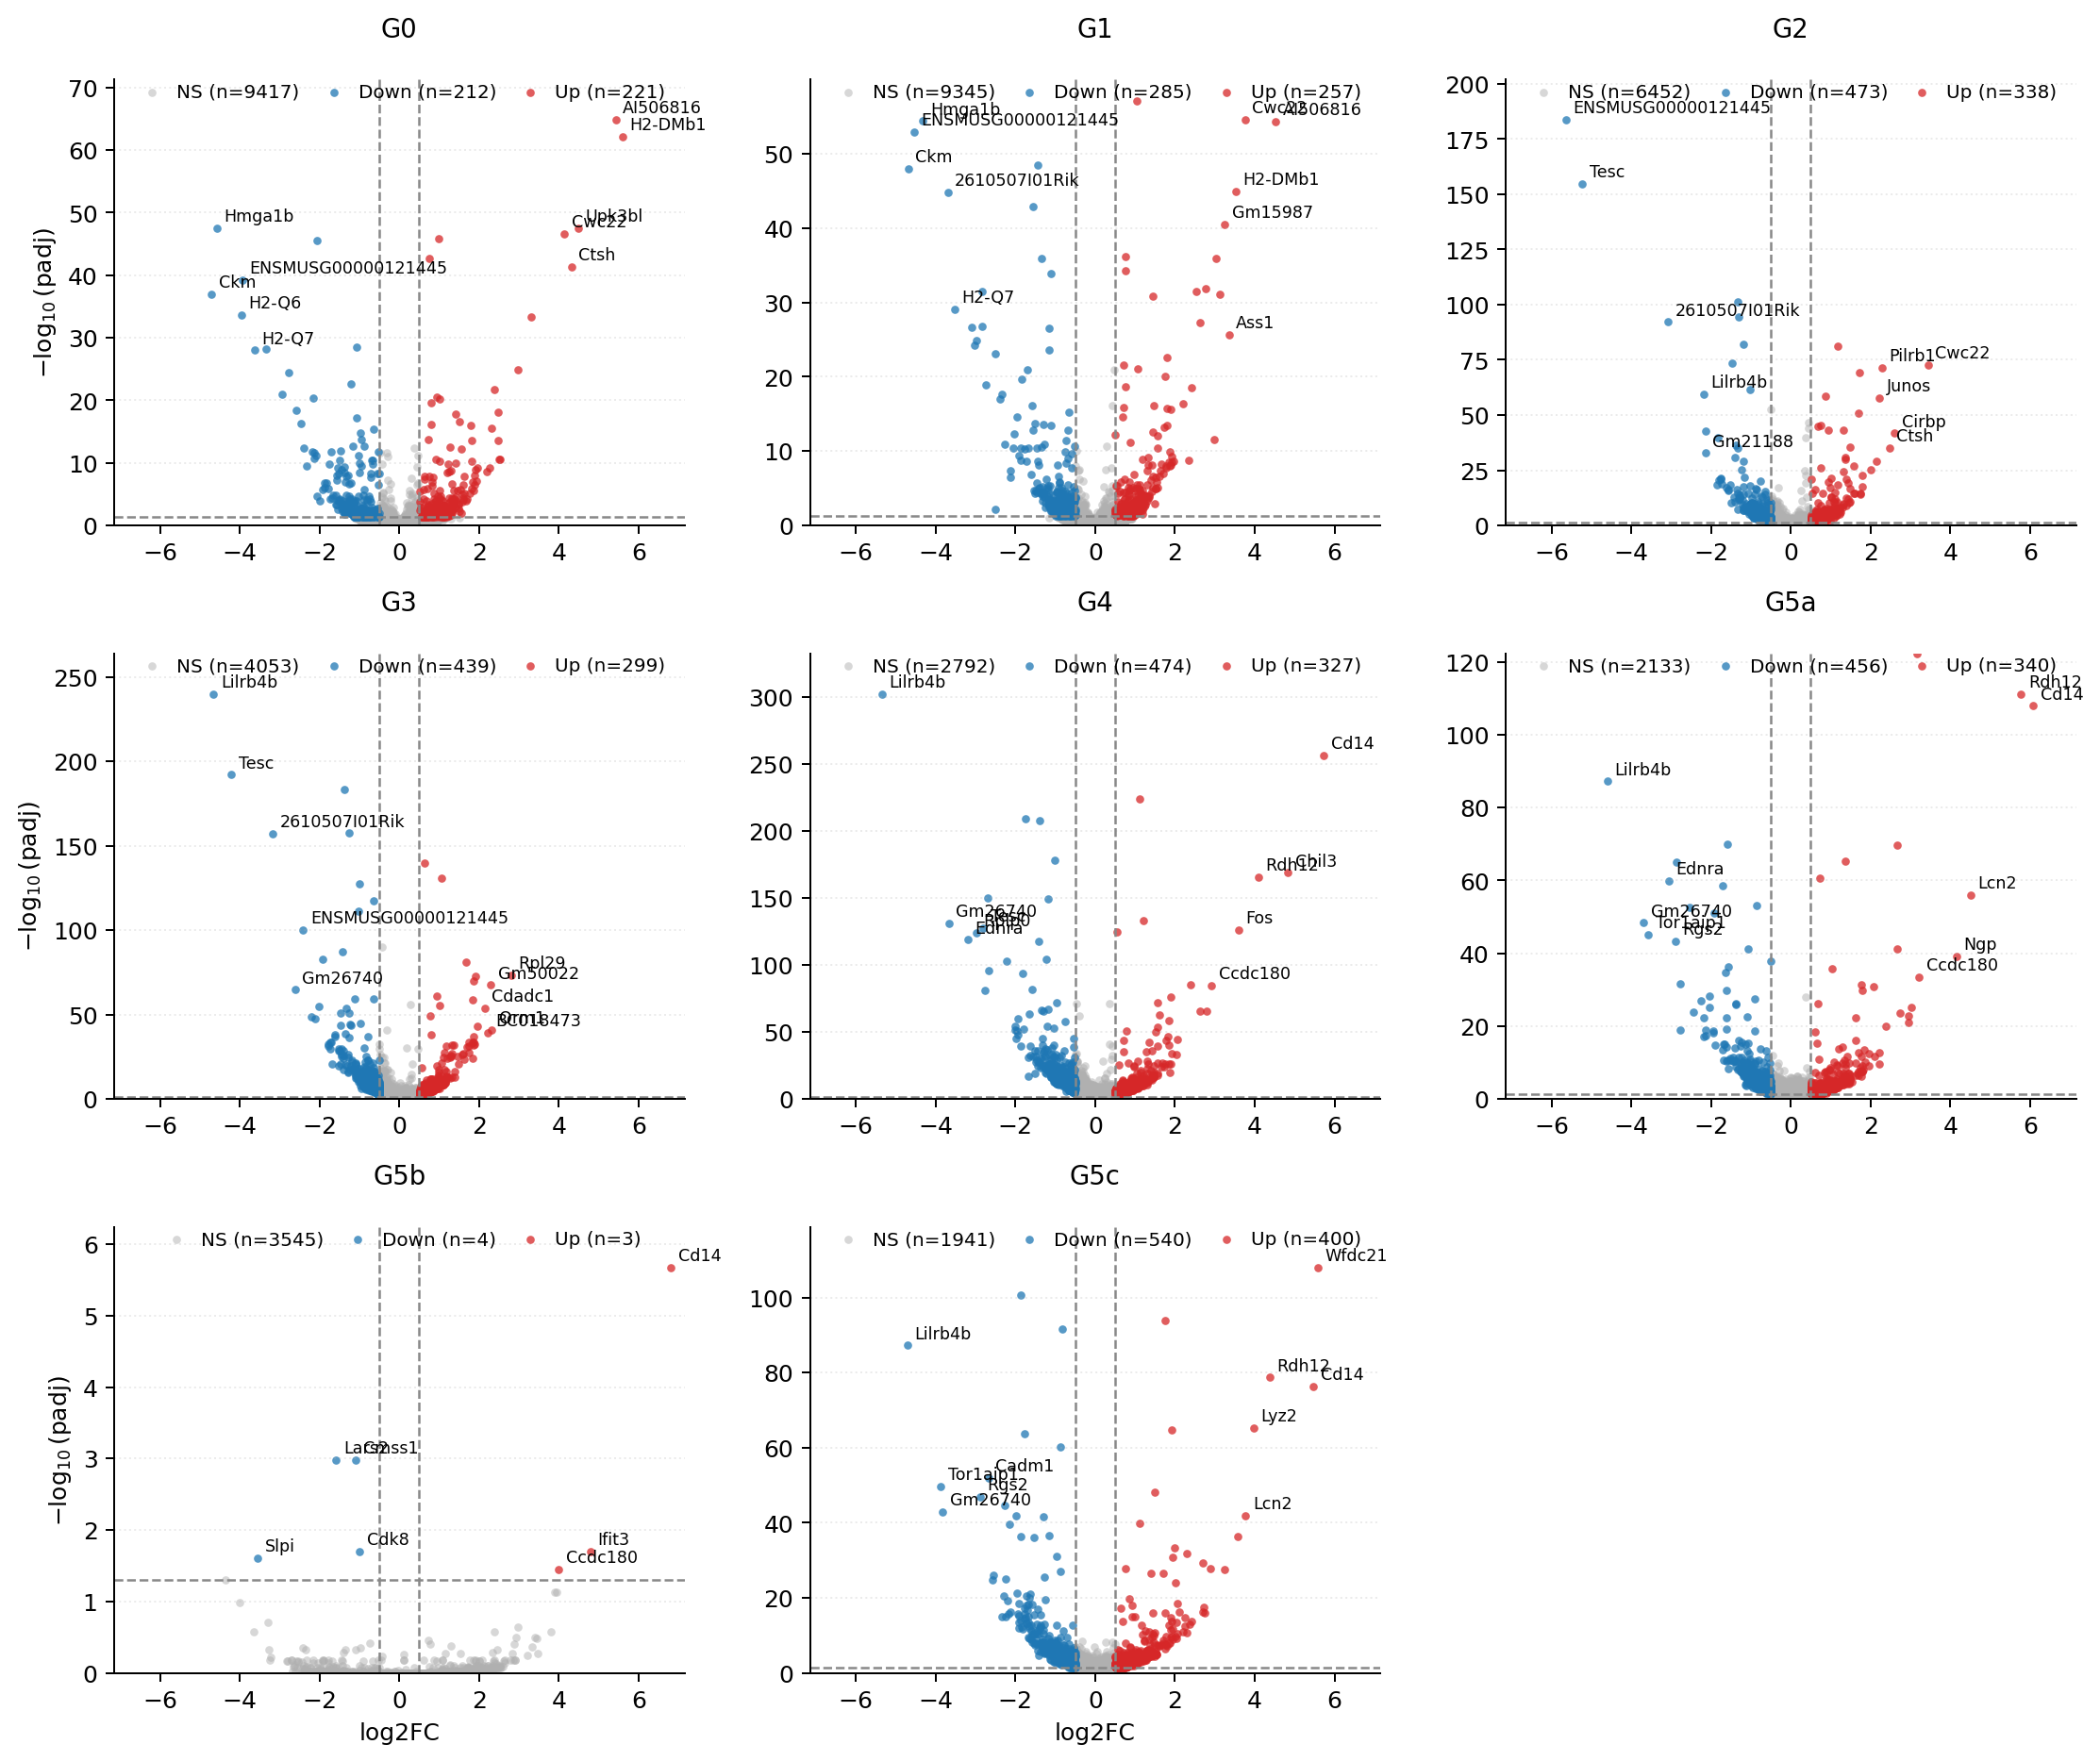

In [19]:
# The file name includes the model used above.
df.to_csv(f"{data_dir}/degs_MAST_glm.tsv", sep="\t", index=False)
display(df[(df.padj < 0.05)].sort_values(["celltype", "padj"]))

VolcanoGridByGroup(df, col_gene="gene_id", lfc_thr=0.5, p_thr=0.05)

### How many genes are "significant"?

Count the significant genes per cell type, with and without a minimum effect
size. With cells as replicates (`model="glm"`), the number of genes with
`padj < 0.05` grows with the number of cells, even when the effects are tiny.
The effect-size filter shows how many of them have a change you could care
about.

In [20]:
sig = df["padj"] < 0.05
big = df["log2FoldChange"].abs() > 0.5   # 0.5 in log2 = 1.4-fold
summary = pd.DataFrame({
    "tested": df.groupby("celltype", observed=True).size(),
    "padj < 0.05": sig.groupby(df["celltype"], observed=True).sum(),
    "padj < 0.05 and |log2FC| > 0.5": (sig & big).groupby(df["celltype"], observed=True).sum(),
})
summary["fraction significant"] = (summary["padj < 0.05"] / summary["tested"]).round(2)
summary

,tested,padj < 0.05,padj < 0.05 and |log2FC| > 0.5,fraction significant
celltype,,,,
G0,9850,569,433,0.06
G1,9887,685,542,0.07
G2,7263,1826,811,0.25
G3,4791,3502,738,0.73
G4,3593,3458,801,0.96
G5a,2929,2036,796,0.70
G5b,3552,7,7,0.00
G5c,2881,1991,940,0.69


**Example dataset:** in one run, the share of tested genes with `padj < 0.05`
grew with the number of cells: 7% in G0 (346 cells), 25% in G2 (1,239 cells),
73% in G3 (2,658 cells) and 95% in G4 (3,231 cells). Half of the significant
genes had `|log2FC| < 0.1` (a change of about 7%), and the median was 0.10. With
`|log2FC| > 0.5`, only 20 to 157 genes per stage remained. G5b (79 SPF vs 24 GF
cells) passed `min_cells_per_group=20`, but with so few cells only 8 genes were
significant.

This is what pseudoreplication looks like: with many cells, almost any
difference between the two animals passes the test. So rank genes by effect
size and detection, and use `padj` only as a first filter.

As an example of a known result, *Hcar2*, reported higher in GF neutrophils by
Sheng et al. (2025), had `log2FoldChange` 0.45 in G5a and 0.66 in G5c, and was
detected in about 12-14% of SPF cells and 30-33% of GF cells. This agrees with
the paper, but it is still a comparison of two animals.

# Limits of interpretation

**About MAST**

- With `model="glm"`, cells are the replicates. With several samples per
  condition, p-values are too small (pseudoreplication). Prefer `glmer` or
  pseudobulk when there are replicates [Zimmerman et al., 2021; Squair et al., 2021].
- The fold change is a change in mean log-expression (hurdle), not a ratio of
  mean counts. It depends on `target_sum`, so it cannot be compared directly with
  pseudobulk DESeq2 fold changes.
- `padj` is corrected inside each cell type, not across all cell types.
- Differential expression is not the same as a change in cell state or
  function. Composition differences between conditions are handled only by
  testing each cell type separately.

**Next steps**

- The `stat` column ranks all tested genes, so it can be used for pathway
  activity (ULM) or GSEA, e.g. with `sctools.functionalanalysis.PrepareULMInput`.
  Drop the rows where the LRT failed first: `df.dropna(subset=["stat"])`.

**About the example dataset**

- One animal per condition: GF vs SPF differences cannot be separated from
  differences between the two animals or libraries.
- The gene lists are hypotheses. Confirm them in data with biological
  replicates.

References:

- [Finak et al., 2015: MAST: a flexible statistical framework for assessing
  transcriptional changes and characterizing heterogeneity in single-cell RNA
  sequencing data](https://doi.org/10.1186/s13059-015-0844-5).
- [Soneson and Robinson, 2018: Bias, robustness and scalability in single-cell
  differential expression analysis](https://doi.org/10.1038/nmeth.4612).
- [Gelman et al., 2008: A weakly informative default prior distribution for
  logistic and other regression models](https://doi.org/10.1214/08-AOAS191).
- [Crowell et al., 2020: muscat detects subpopulation-specific state
  transitions from multi-sample multi-condition single-cell transcriptomics
  data](https://doi.org/10.1038/s41467-020-19894-4).
- [Zimmerman et al., 2021: A practical solution to pseudoreplication bias in
  single-cell studies](https://doi.org/10.1038/s41467-021-21038-1).
- [Squair et al., 2021: Confronting false discoveries in single-cell
  differential expression](https://doi.org/10.1038/s41467-021-25960-2).
- [Xie et al., 2020: Single-cell transcriptome profiling reveals neutrophil
  heterogeneity in homeostasis and infection](https://doi.org/10.1038/s41590-020-0736-z).
- [Sheng et al., 2025: Single-cell RNA-seq provides insight into the
  underdeveloped immune system of germ-free mice](https://doi.org/10.24272/j.issn.2095-8137.2024.467).